HUC2 CRS before assignment: None
HUC2 bounds before transformation:
[-7783576.02289802  2187575.63815253  3619690.05690435 10257816.27458091]
HUC2 CRS after assignment: EPSG:26915
HUC2 CRS after transformation: EPSG:4326
HUC2 bounds after transformation:
[-179.96928239   17.67456073  179.91556688   71.39676244]

HUC2 columns:
['HUC2', 'COUNT', 'REG_NAME', 'ACRES', 'geometry']

Using HUC2 column: HUC2

HUC2 codes found:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21']

The following HUC2 regions were not assigned:
['19', '20', '21']

PUR REGION SUMMARY
   PUR_region                                           geometry
0           1  MULTIPOLYGON (((-75.90469 37.11406, -75.91338 ...
1           2  MULTIPOLYGON (((-97.21938 26.01343, -97.2179 2...
2           3  POLYGON ((-105.67422 40.27259, -105.6871 40.28...
3           4  MULTIPOLYGON (((-83.07339 29.09564, -83.07442 ...
4           5  MULTIPOLYGON (((-77.8569

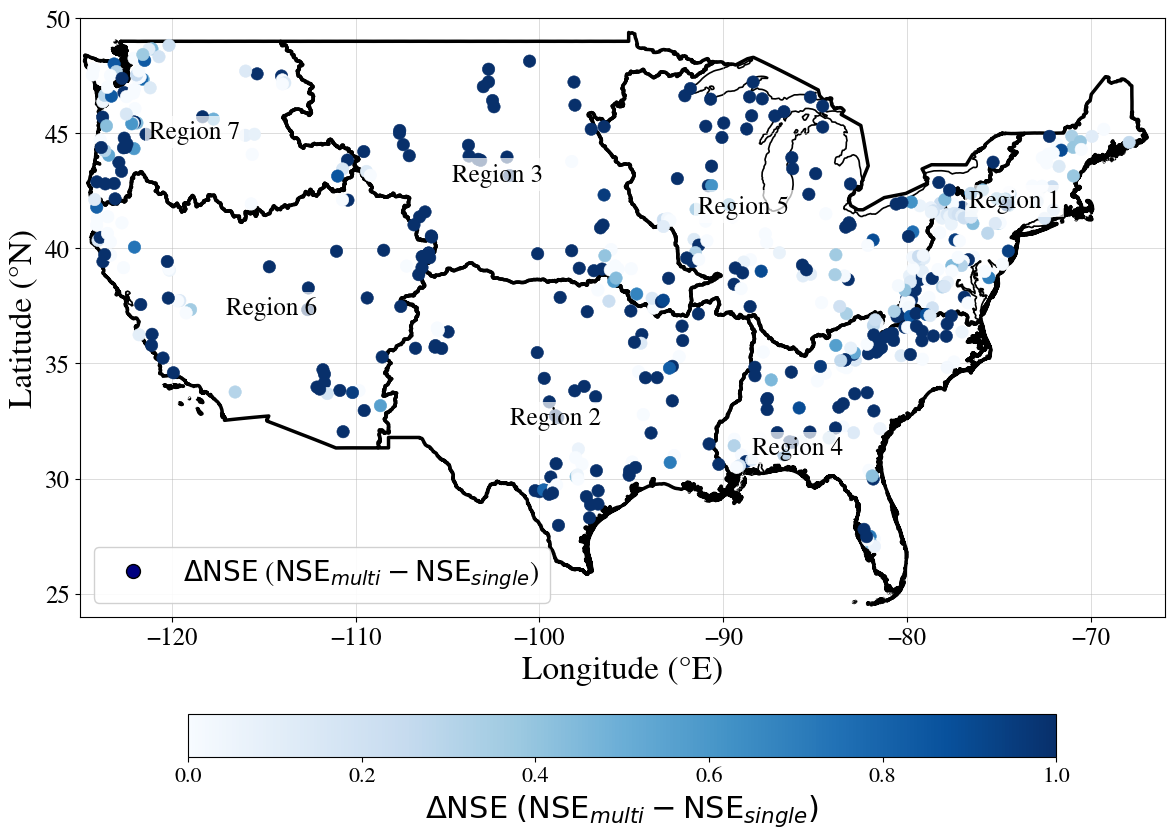

marrmot_PRMS USGS


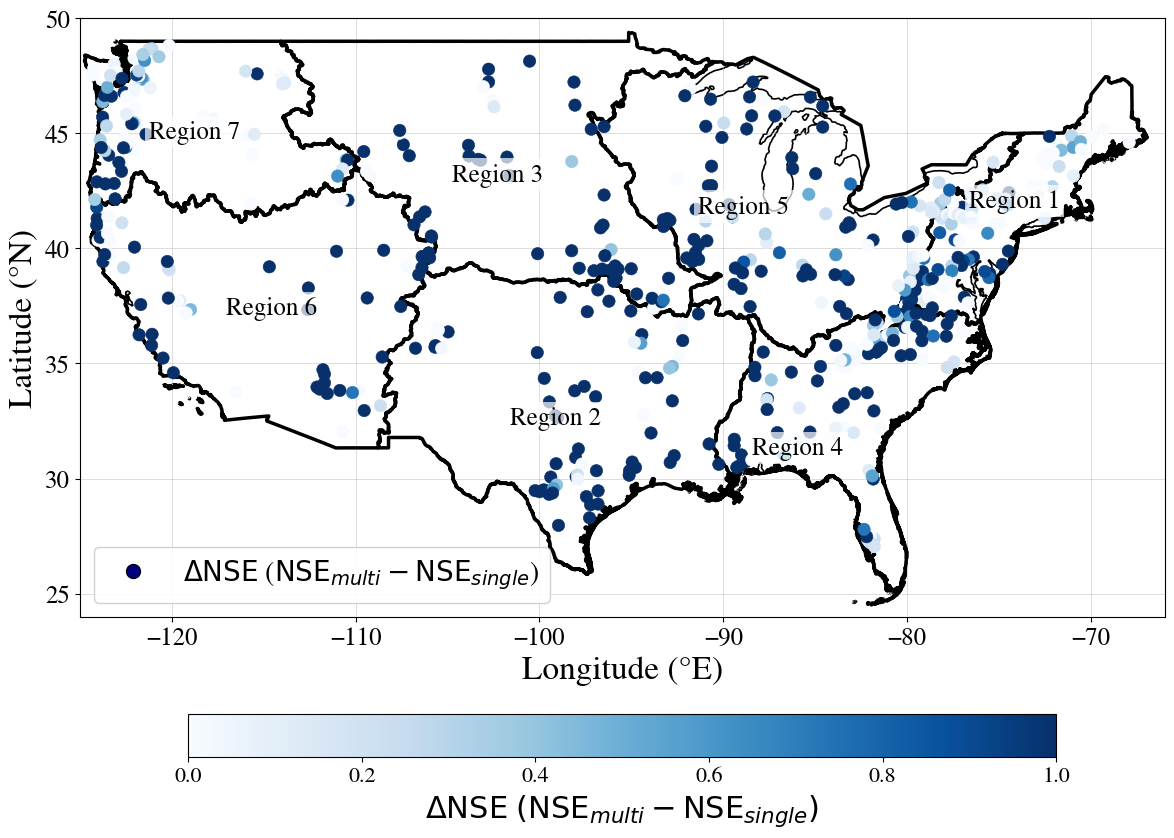

HBV_capillary USGS


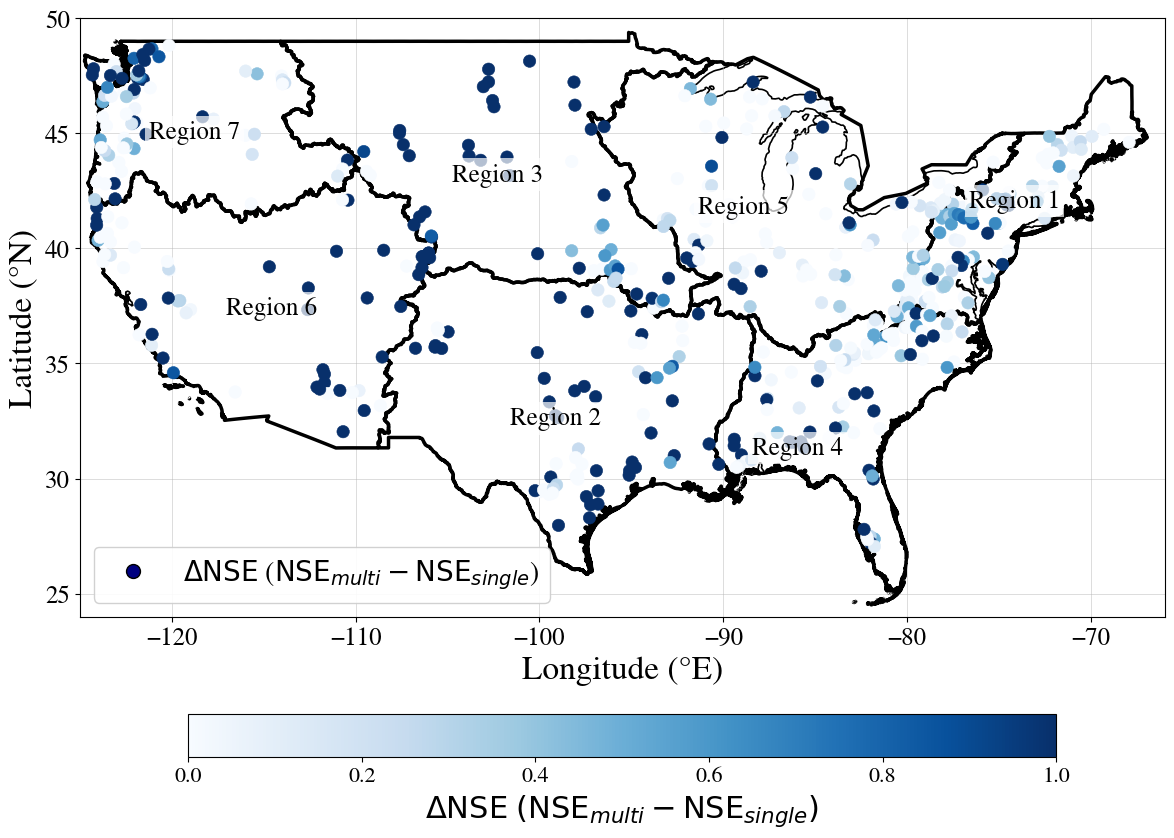

HBV Furey


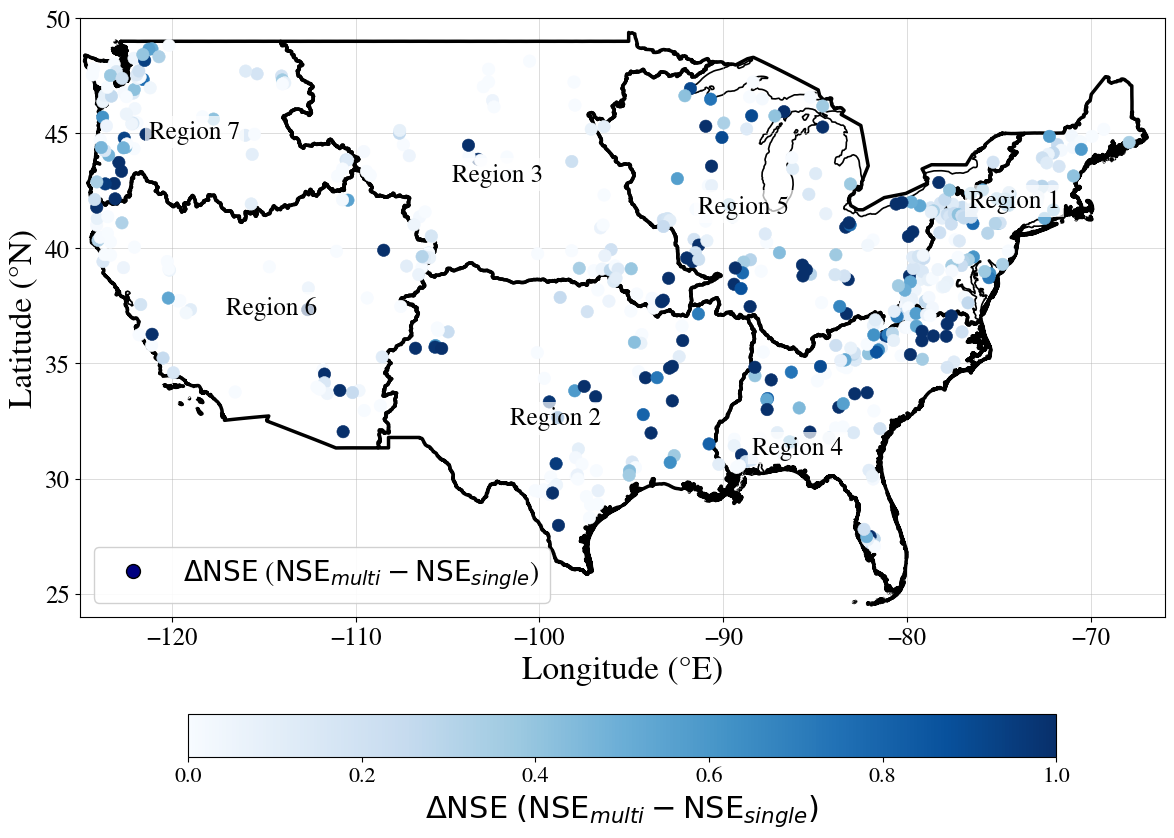

marrmot_PRMS Furey


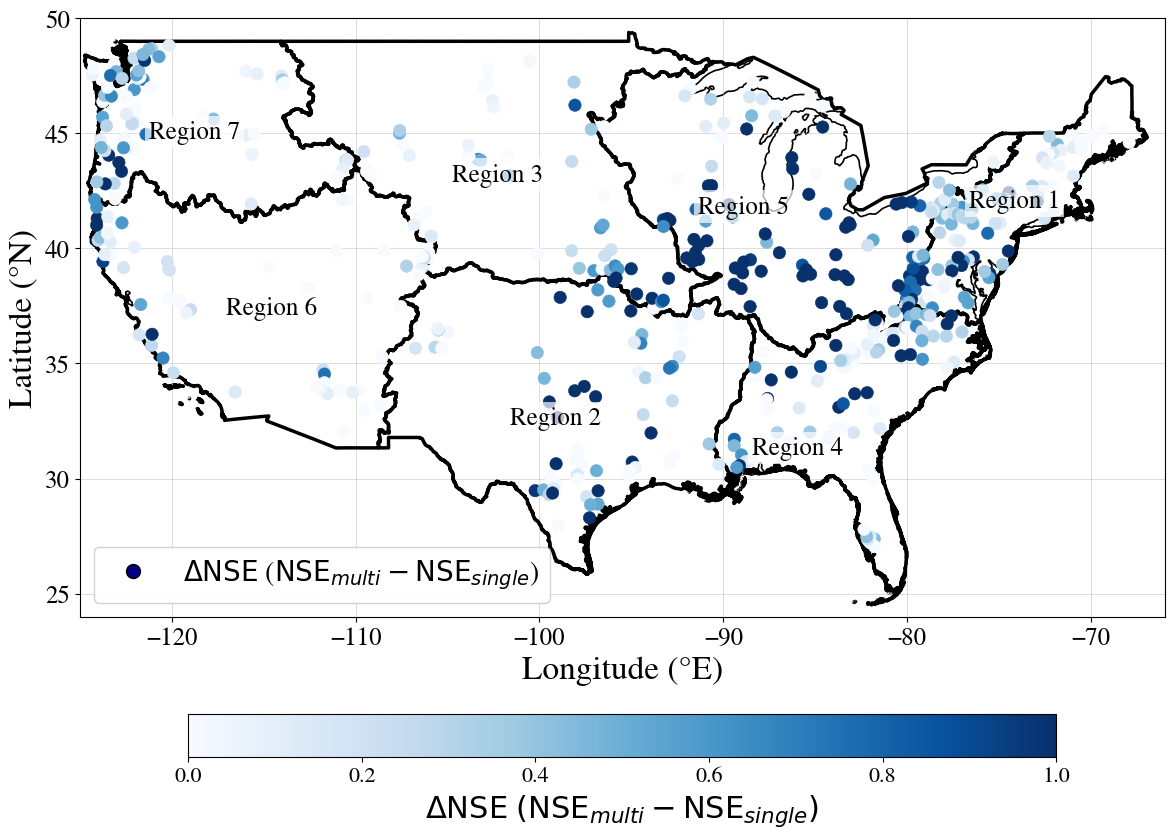

HBV_capillary Furey


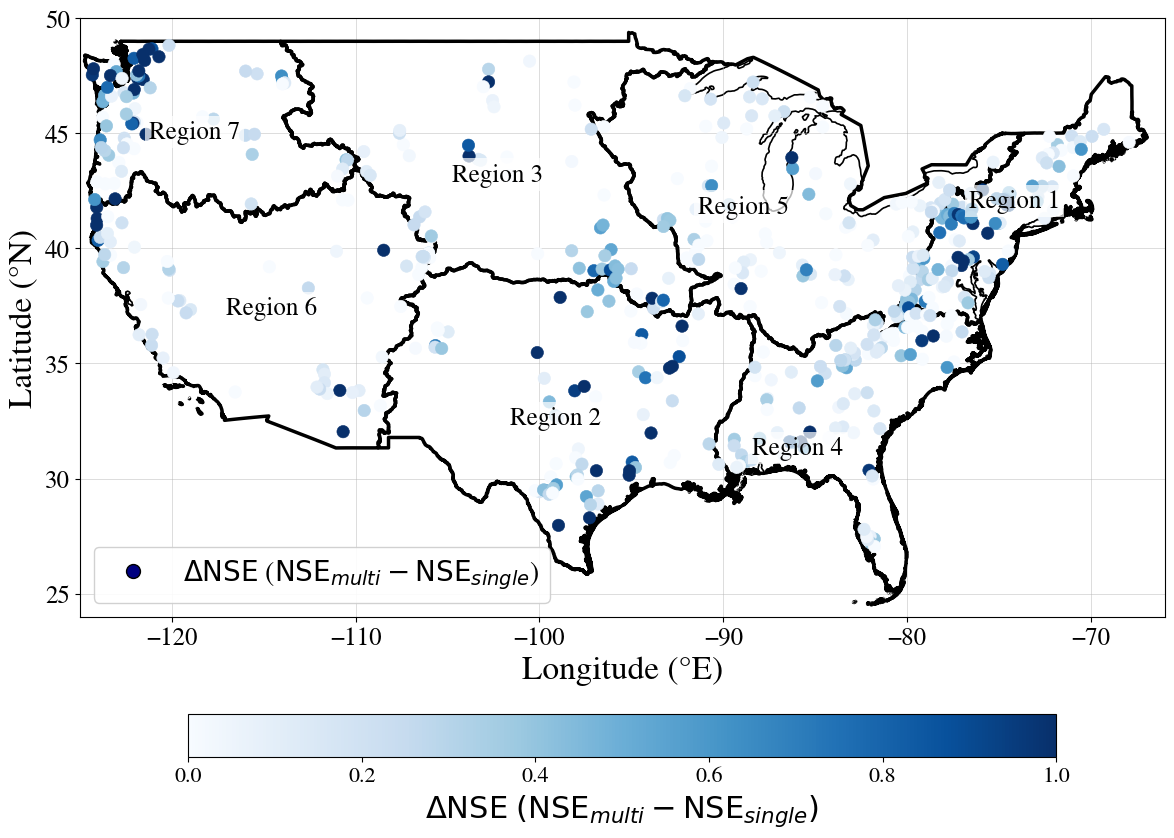

HBV Eckhardt


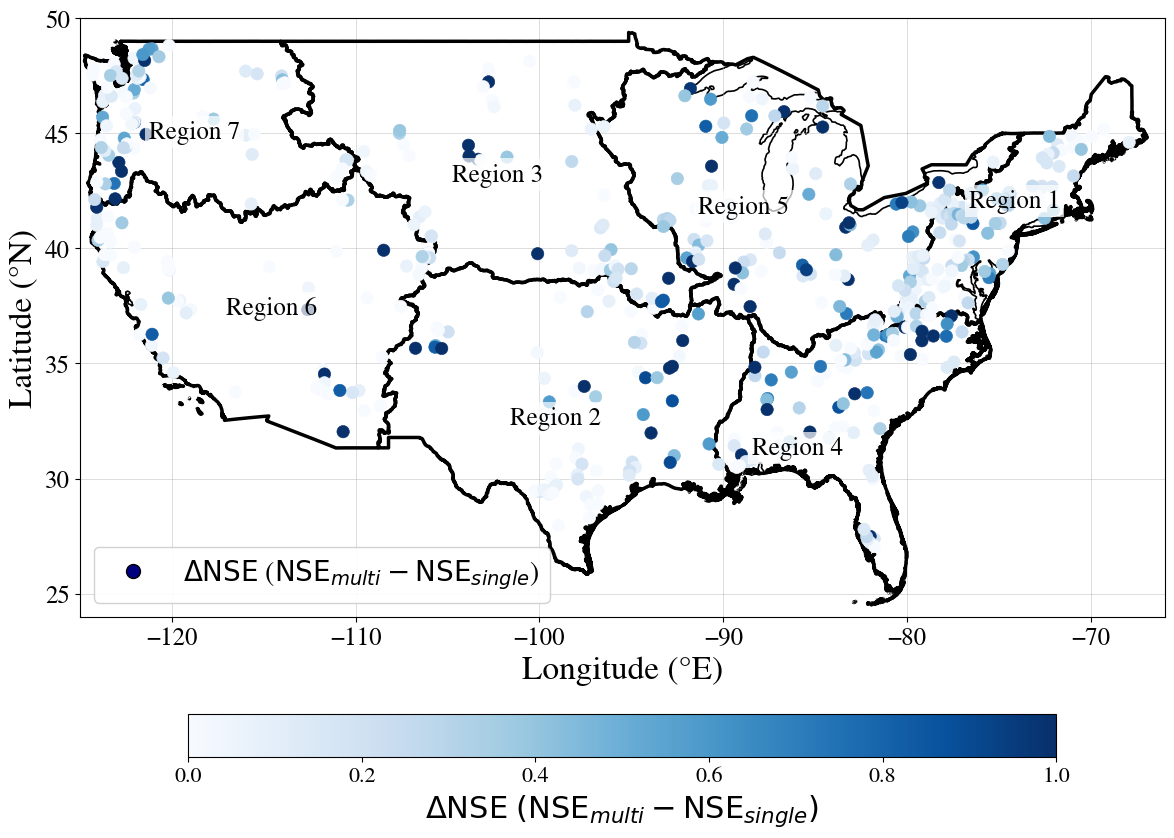

marrmot_PRMS Eckhardt


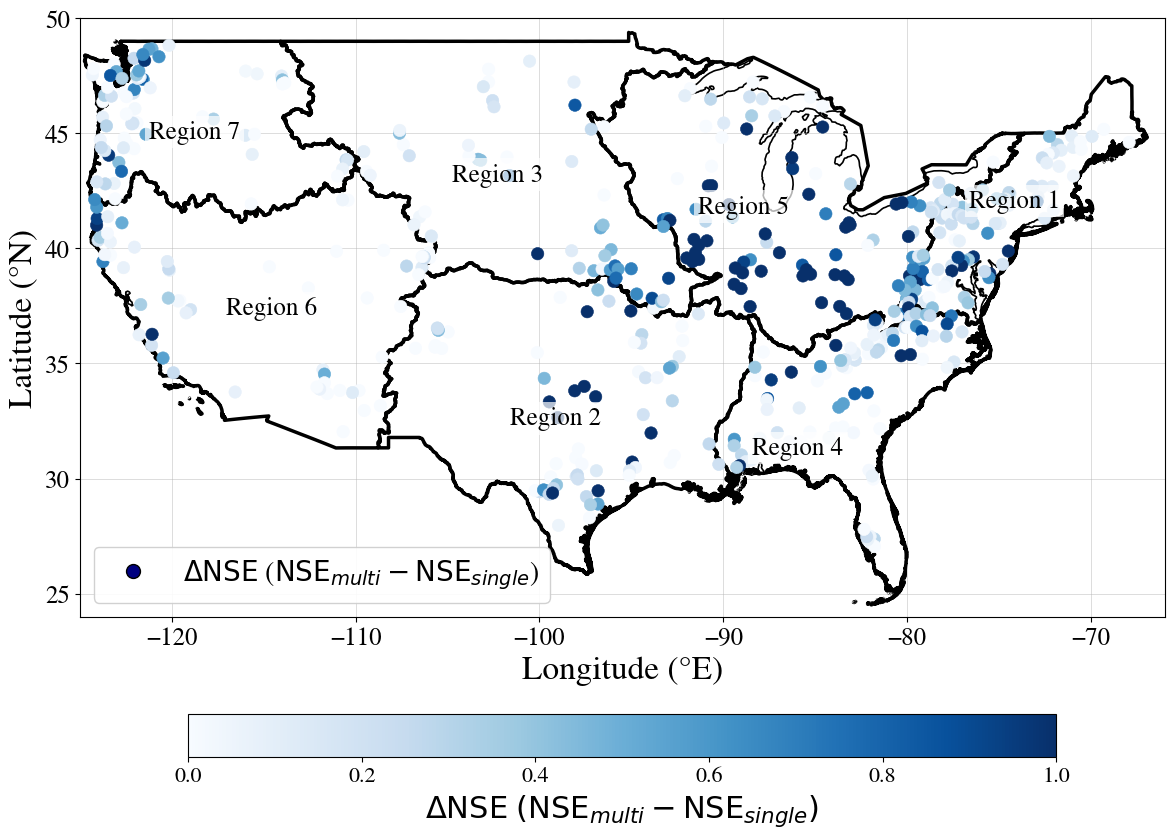

HBV_capillary Eckhardt


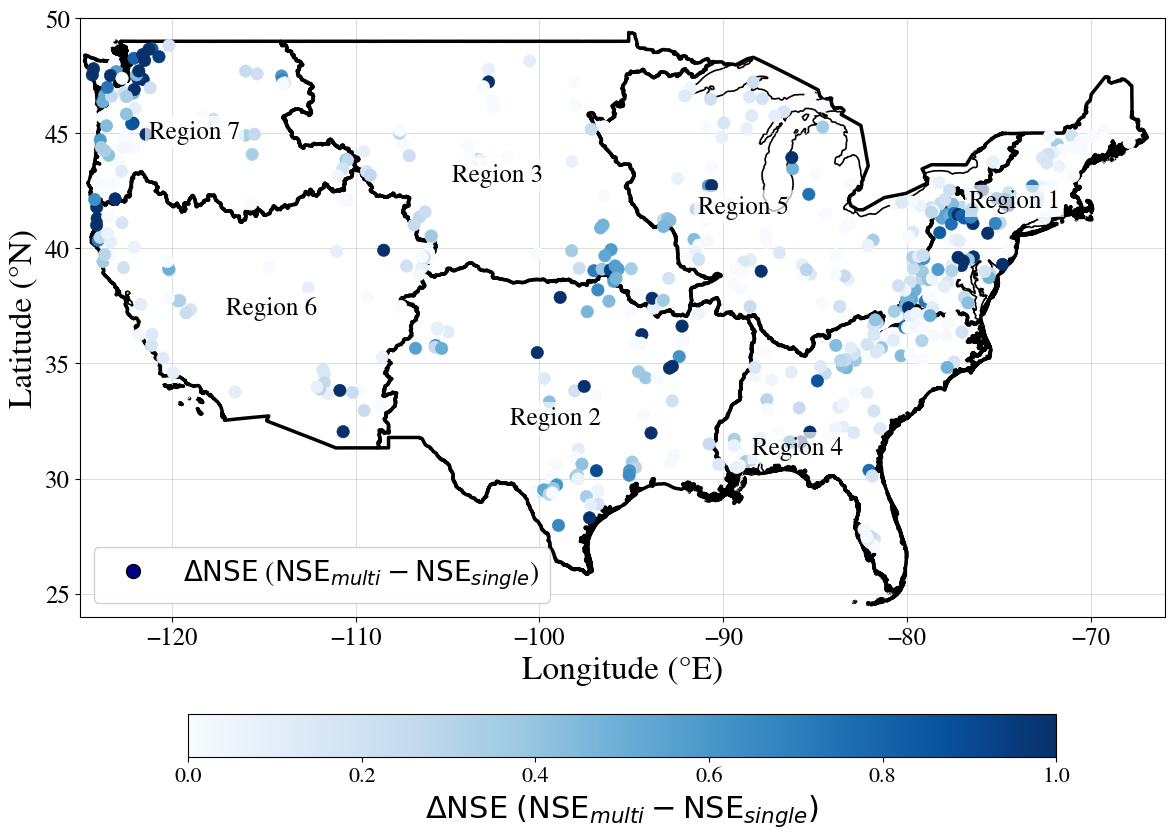

HBV LocalHYSEP


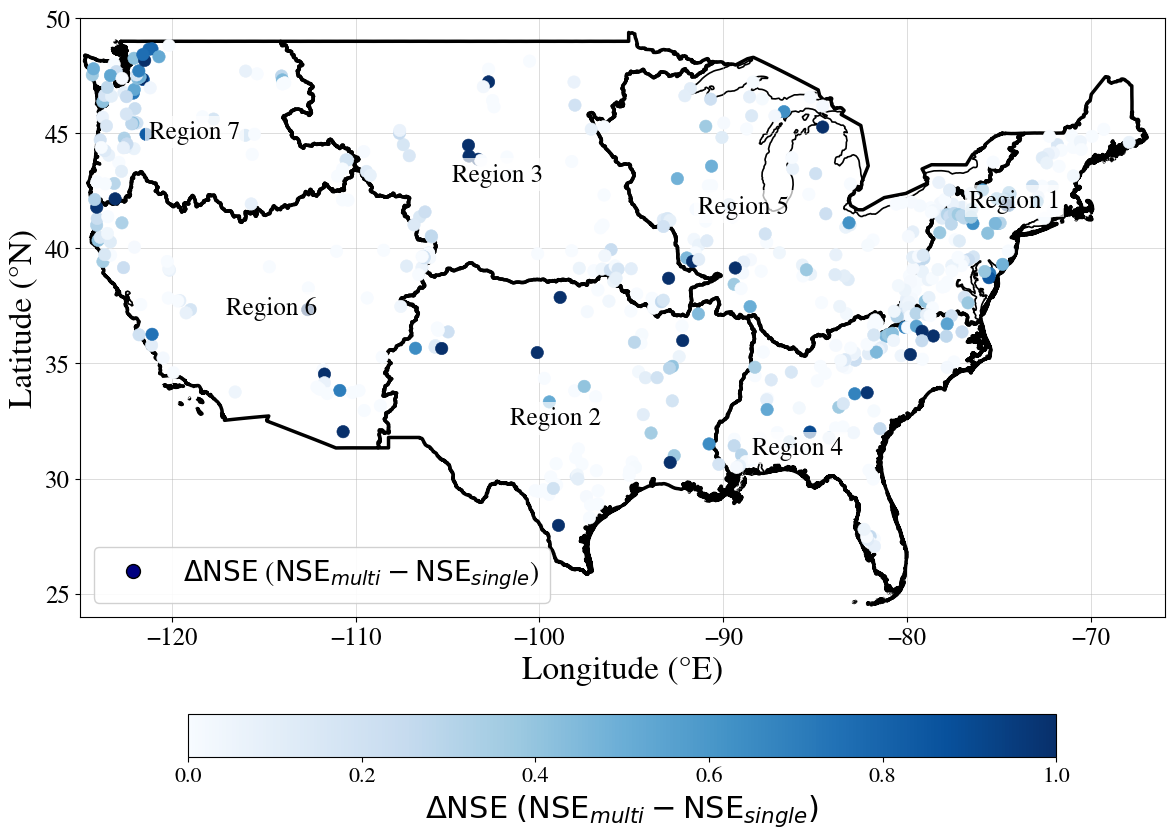

marrmot_PRMS LocalHYSEP


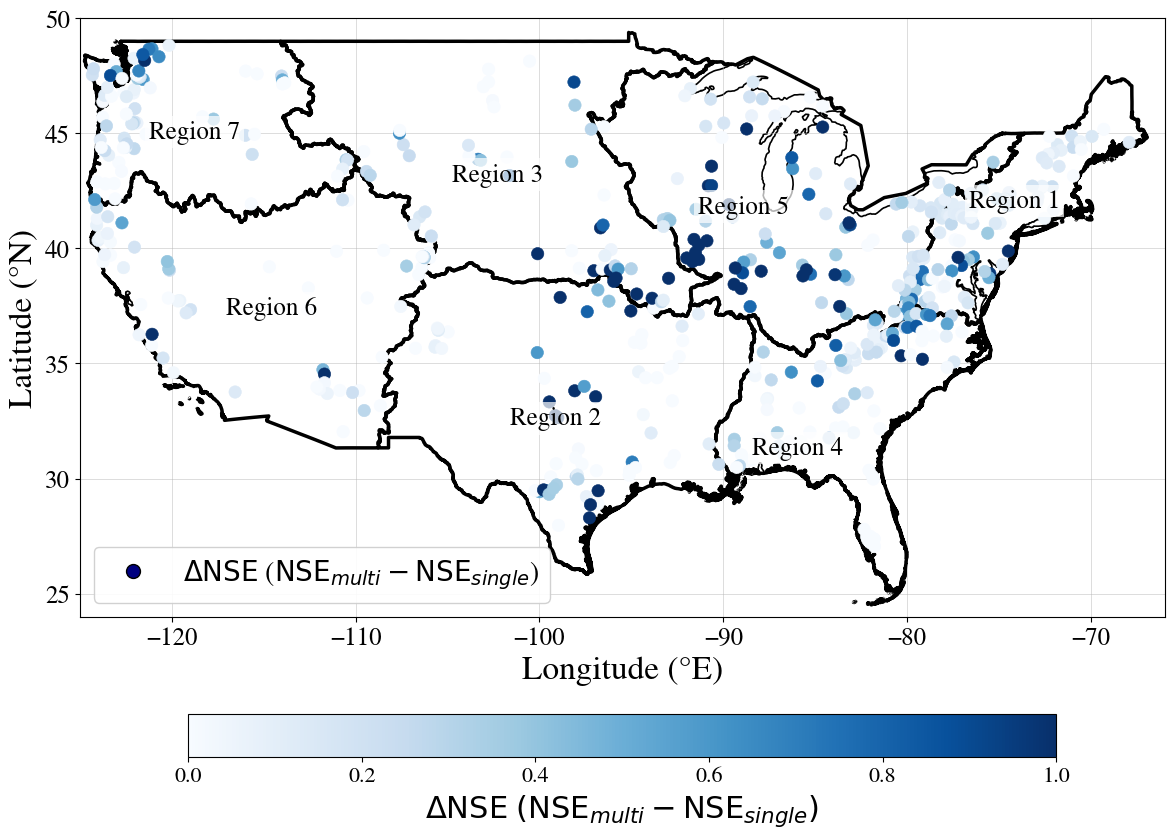

HBV_capillary LocalHYSEP


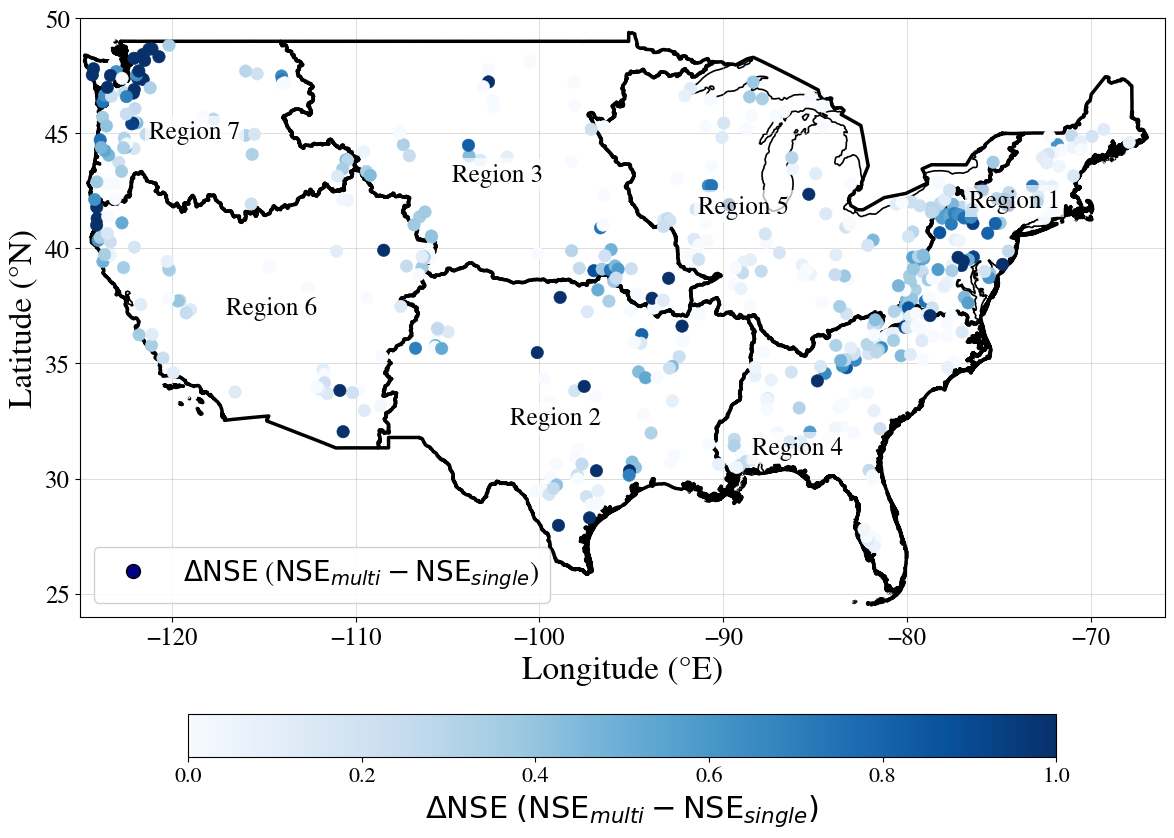

In [4]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

plt.rcParams['font.family']= 'Nimbus Roman'

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)


# ============================================================
# PUR REGION DEFINITION FROM FENG ET AL.
# ============================================================

pur_groups = {
    1: ['01', '02'],
    2: ['08', '11', '12', '13'],
    3: ['09', '10'],
    4: ['03', '06'],
    5: ['04', '05', '07'],
    6: ['14', '15', '16', '18'],
    7: ['17']
}

# ------------------------------------------------------------
# Make sure HUC2 codes are strings with leading zero
# ------------------------------------------------------------

gdf_huc2 = gpd.read_file("/home/s0shar47/scratch/huc_02/huc_02.shp")

print("HUC2 CRS before assignment:", gdf_huc2.crs)
print("HUC2 bounds before transformation:")
print(gdf_huc2.total_bounds)
gdf_huc2 = gdf_huc2.set_crs(
    "EPSG:26915"
)

print("HUC2 CRS after assignment:", gdf_huc2.crs)


# ============================================================
# TRANSFORM HUC2 TO WGS84
# ============================================================

gdf_huc2 = gdf_huc2.to_crs(
    "EPSG:4326"
)

print("HUC2 CRS after transformation:", gdf_huc2.crs)
print("HUC2 bounds after transformation:")
print(gdf_huc2.total_bounds)


# ============================================================
# CHECK HUC2 COLUMNS
# ============================================================

print("\nHUC2 columns:")
print(gdf_huc2.columns.tolist())


possible_huc_columns = [
    "HUC2",
    "HUC_2",
    "HUC2_CODE",
    "HUC_02",
    "HUC_02_",
    "HUC2_",
    "HUC"
]

huc_column = None

for col in possible_huc_columns:

    if col in gdf_huc2.columns:
        huc_column = col
        break

if huc_column is None:

    raise ValueError(
        "\nCould not identify the HUC2 column.\n"
        "Available columns are:\n"
        + str(gdf_huc2.columns.tolist())
    )

print("\nUsing HUC2 column:", huc_column)


# ============================================================
# STANDARDIZE HUC2 CODES
# ============================================================

gdf_huc2["HUC2_CODE"] = (
    gdf_huc2[huc_column]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
    .str.zfill(2)
)

print("\nHUC2 codes found:")
print(
    sorted(
        gdf_huc2["HUC2_CODE"].unique()
    )
)


# ============================================================
# CREATE HUC2 -> PUR REGION LOOKUP
# ============================================================

huc_to_region = {}

for region, hucs in pur_groups.items():

    for huc in hucs:

        huc_to_region[huc] = region


# ============================================================
# ASSIGN PUR REGION
# ============================================================

gdf_huc2["PUR_region"] = (
    gdf_huc2["HUC2_CODE"]
    .map(huc_to_region)
)


# Check whether any HUC2 was not assigned
unassigned = gdf_huc2[
    gdf_huc2["PUR_region"].isna()
]

if len(unassigned) > 0:

    print("\nWARNING:")
    print("The following HUC2 regions were not assigned:")
    print(
        unassigned["HUC2_CODE"]
        .tolist()
    )


# ============================================================
# KEEP PUR REGIONS
# ============================================================

gdf_pur = gdf_huc2.dropna(
    subset=["PUR_region"]
).copy()

gdf_pur["PUR_region"] = (
    gdf_pur["PUR_region"]
    .astype(int)
)


# ============================================================
# DISSOLVE HUC2 INTO PUR REGIONS
# ============================================================

gdf_pur_regions = (
    gdf_pur
    .dissolve(
        by="PUR_region"
    )
    .reset_index()
)


print("\n" + "=" * 70)
print("PUR REGION SUMMARY")
print("=" * 70)

print(
    gdf_pur_regions[
        ["PUR_region", "geometry"]
    ]
)


# ============================================================
# CREATE BASIN POINTS
# ============================================================

print("\n" + "=" * 70)
print("CREATING BASIN POINTS")
print("=" * 70)


## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

method= 'LocalHYSEP'
methods= ['USGS', 'Furey', 'Eckhardt', 'LocalHYSEP']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'

for method in methods:
    for model in models:
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/{method}_Multi/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/{method}_Multi/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/{method}_Multi/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/{method}_Multi/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)

        # Create the plot figure
        fig, ax = plt.subplots(figsize=(14, 14))
        # 1. Plot the map outline backdrop first
        gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)
        # 2. Plot Single-Objective performance markers (Square shape)
        scatter1 = ax.scatter(
            table['lon'], table['lat'], 
            marker='o', s=80, 
            c=table['NSE-Flow (Single-Objective)'], 
            cmap='Blues', vmin=0.2, vmax=1,  # Set color limits for clear NSE comparison
            label='Single-Objective', zorder=2
        )
        # 4. Generate discrete colorbars for both objectives
        cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
        cbar1.set_label('NSE Flow (Single-Objective)')
        # 5. Finalize legend and axis view configurations
        plt.legend(loc='upper right', fontsize=15)
        ax.set_title("CONUS Streamflow Model Evaluation: NSE Flow Metrics", fontsize=18, fontweight='bold', pad=15)
        # ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
        plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
        plt.ylabel('Latitude (°N)', fontsize=15)
        plt.xticks(fontsize=15)
        plt.yticks(fontsize=15)
        plt.grid()
        # plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/NSE_MAPS/{test}/Single/Total_Flow_{model}.jpg",dpi=400)
        plt.close()

        # Create the plot figure
        fig, ax = plt.subplots(figsize=(14, 14))
        # 1. Plot the map outline backdrop first
        gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)
        # 3. Plot Multi-Objective performance markers (Circle shape)
        scatter2 = ax.scatter(
            table['lon'], table['lat'], 
            marker='o', s=80, 
            c=table['NSE-Flow (Multi-Objective)'], 
            cmap='Blues', vmin=0.2, vmax=1,
            label='Multi-Objective', zorder=3
        )
        cbar2 = fig.colorbar(scatter2, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
        cbar2.set_label('NSE Flow (Multi-Objective)')
        # 5. Finalize legend and axis view configurations
        plt.legend(loc='upper right', fontsize=15)
        ax.set_title("CONUS Streamflow Model Evaluation: NSE Flow Metrics", fontsize=16, fontweight='bold', pad=15)
        plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
        plt.ylabel('Latitude (°N)', fontsize=15)
        plt.xticks(fontsize=15)
        plt.yticks(fontsize=15)
        plt.grid()
        # plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/NSE_MAPS/{test}/{method}/Total_Flow_{model}.jpg",dpi=400)
        plt.close()


        # Create the plot figure
        fig, ax = plt.subplots(figsize=(14, 14))
        # 1. Plot the map outline backdrop first
        gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)
        # 2. Plot Single-Objective performance markers (Square shape)
        scatter1 = ax.scatter(
            table['lon'], table['lat'], 
            marker='o', s=80, 
            c=table['NSE-Baseflow (Single-Objective)'], 
            cmap='Blues', vmin=0.2, vmax=1,  # Set color limits for clear NSE comparison
            label='Single-Objective', zorder=2
        )
        # 4. Generate discrete colorbars for both objectives
        cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
        cbar1.set_label('NSE Baseflow (Single-Objective)')
        # 5. Finalize legend and axis view configurations
        plt.legend(loc='upper right', fontsize=15)
        ax.set_title("CONUS Streamflow Model Evaluation: NSE Baseflow Metrics", fontsize=18, fontweight='bold', pad=15)
        # ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
        plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
        plt.ylabel('Latitude (°N)', fontsize=15)
        plt.xticks(fontsize=15)
        plt.yticks(fontsize=15)
        plt.grid()
        # plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/NSE_MAPS/{test}/Single/Baseflow_{model}.jpg",dpi=400)
        plt.close()


        # Create the plot figure
        fig, ax = plt.subplots(figsize=(14, 14))

        # 1. Plot the map outline backdrop first
        gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)

        # 3. Plot Multi-Objective performance markers (Circle shape)
        scatter2 = ax.scatter(
            table['lon'], table['lat'], 
            marker='o', s=80, 
            c=table['NSE-Baseflow (Multi-Objective)'], 
            cmap='Blues', vmin=0.2, vmax=1,
            label='Multi-Objective', zorder=3
        )

        cbar2 = fig.colorbar(scatter2, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
        cbar2.set_label('NSE Baseflow (Multi-Objective)')

        # 5. Finalize legend and axis view configurations
        plt.legend(loc='upper right', fontsize=15)
        ax.set_title("CONUS Model Evaluation: NSE Baseflow Metrics", fontsize=18, fontweight='bold', pad=15)
        # ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
        plt.xlabel('Longitude(°E)', fontsize=15)
        plt.ylabel('Latitude(°N)', fontsize=15)
        plt.grid()
        # plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/NSE_MAPS/{test}/{method}/Baseflow_{model}.jpg",dpi=400)
        plt.close()


        # Create the plot figure
        fig, ax = plt.subplots(figsize=(14, 14))

        # 1. Plot the map outline backdrop first
        gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)

        # 2. Plot performance markers
        scatter1 = ax.scatter(
            table['lon'], table['lat'], 
            marker='o', s=80, 
            c=(table['NSE-Flow (Multi-Objective)'] - table['NSE-Flow (Single-Objective)']), 
            cmap='seismic_r', 
            vmin=-0.4, 
            vmax=0.4,  
            label=r'$\text{NSE}_{\mathit{multi}} - \text{NSE}_{\mathit{single}}$', 
            zorder=2
        )

        # 4. Generate discrete colorbar
        cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
        cbar1.set_label(r'$\Delta\text{NSE}\ (\text{NSE}_{\mathit{multi}} - \text{NSE}_{\mathit{single}})$', fontsize=14)
        cbar1.ax.tick_params(labelsize=12)

        # 5. Finalize legend and axis view configurations
        leg = plt.legend(loc='upper right', fontsize=14, framealpha=1.0, facecolor='white', edgecolor='gray')

        # FORCE LEGEND ICON COLOR TO BE VISIBLE (Changes it from invisible white to solid dark blue/grey)
        for handle in leg.legend_handles:
            handle.set_color('#1f77b4')  # Solid blue color for the legend reference circle
            handle.set_sizes([100])      # Makes the legend circle slightly larger for readability

        ax.set_title("CONUS Streamflow Model Evaluation: Change in NSE Flow Metrics", fontsize=18, fontweight='bold', pad=15)
        plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
        plt.ylabel('Latitude (°N)', fontsize=15)
        plt.xticks(fontsize=15)
        plt.yticks(fontsize=15)
        plt.grid()
        # plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/NSE_MAPS/{test}/{method}/Delta_Total_Flow_{model}.jpg",dpi=400)
        plt.close()

        # ============================================================
        # Create the Delta Baseflow NSE plot
        # ============================================================

        fig, ax = plt.subplots(figsize=(14, 14))

        # ============================================================
        # 1. CONUS MAP OUTLINE
        # ============================================================

        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=1.2,
            zorder=1
        )

        # ============================================================
        # 2. PUR REGION BOUNDARIES
        # ============================================================

        gdf_pur_regions.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=2.5,
            zorder=3
        )

        # ============================================================
        # 3. DELTA BASEFLOW NSE
        # ============================================================

        delta_nse = (
            table['NSE-Baseflow (Multi-Objective)']
            - table['NSE-Baseflow (Single-Objective)']
        )

        scatter1 = ax.scatter(
            table['lon'],
            table['lat'],
            marker='o',
            s=80,
            c=delta_nse,
            cmap='Blues',
            vmin=0,
            vmax=1,
            # edgecolor='black',
            linewidth=0.4,
            zorder=4
        )

        # ============================================================
        # 4. COLORBAR
        # ============================================================

        cbar1 = fig.colorbar(
            scatter1,
            ax=ax,
            orientation='horizontal',
            pad=0.09,
            shrink=0.8
        )

        cbar1.set_label(
            r'$\Delta\mathrm{NSE}\;'
            r'(\mathrm{NSE}_{\mathit{multi}}'
            r' - '
            r'\mathrm{NSE}_{\mathit{single}})$',
            fontsize=22
        )

        cbar1.ax.tick_params(labelsize=16)

        # ============================================================
        # 5. PUR REGION LABELS
        # ============================================================

        for _, row in gdf_pur_regions.iterrows():

            # Point guaranteed to lie inside polygon
            label_point = row.geometry.representative_point()

            ax.text(
                label_point.x,
                label_point.y,
                f"Region {int(row['PUR_region'])}",
                fontsize=18,
                ha="center",
                va="center",
                zorder=5,
                bbox=dict(
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.7,
                    pad=3
                )
            )

        # ============================================================
        # 6. CUSTOM LEGEND
        # ============================================================
        # Use a dark marker so the legend symbol is clearly visible.
        # This does NOT change the colors of the actual map points.

        legend_marker = plt.Line2D(
            [0],
            [0],
            marker='o',
            linestyle='None',
            markerfacecolor='navy',
            markeredgecolor='black',
            markersize=10,
            label=(
                r'$\Delta\mathrm{NSE}$ '
                r'($\mathrm{NSE}_{\mathit{multi}}'
                r' - '
                r'\mathrm{NSE}_{\mathit{single}}$)'
            )
        )

        ax.legend(
            handles=[legend_marker],
            loc='lower left',
            fontsize=20,
            frameon=True,
            framealpha=0.9
        )

        # ============================================================
        # 7. AXIS FORMATTING
        # ============================================================

        ax.set_xlabel(
            'Longitude (°E)',
            fontsize=24
        )

        ax.set_ylabel(
            'Latitude (°N)',
            fontsize=24
        )

        ax.tick_params(
            axis='both',
            labelsize=18
        )

        ax.grid(
            True,
            linewidth=0.6,
            alpha=0.5
        )

        # Optional: keep map focused on CONUS
        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        # ============================================================
        # 8. FINAL
        # ============================================================

        print(model, method)

        # plt.savefig(
        #     f"/home/s0shar47/scratch/OUTPUTS_Paper1/Figures/"
        #     f"NSE_MAPS/{test}/{method}/"
        #     f"Delta_Baseflow_{model}.jpg",
        #     dpi=400,
        #     bbox_inches='tight'
        # )

        plt.show()

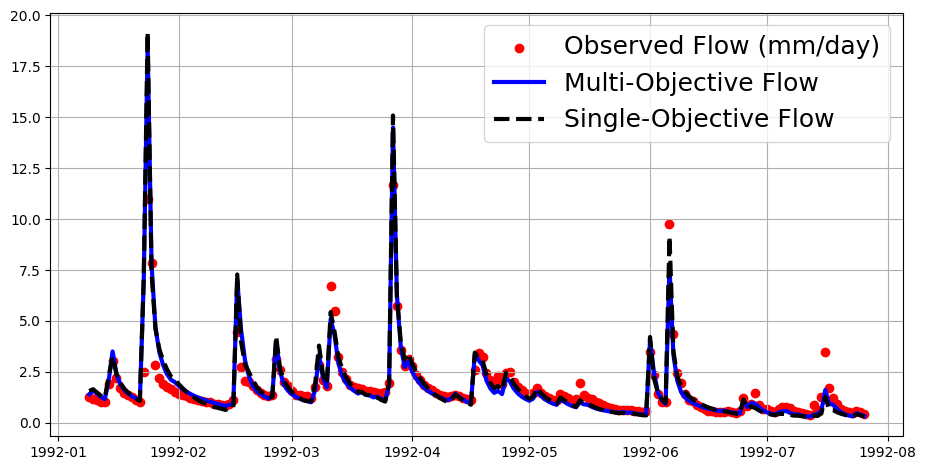

In [4]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

folder= ("/home/s0shar47/scratch/OUTPUTS_Paper1/"
         "PUR/Eckhardt_Multi/Region_1/"
         "LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111"
         "/parBETA_parBETAET_/ts1989_1999/")
sfolder= ("/home/s0shar47/scratch/OUTPUTS_Paper1/"
         "PUR/OUTPUTS_PUR_Single/Region_1/"
         "LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111"
         "/parBETA_parBETAET_/ts1989_1999/")

i=9

obs_flow= np.load(os.path.join(folder,'00060_Mean.npy'))
obs_flow= obs_flow[:,i]

obs_baseflow= np.load(os.path.join(folder,'baseflow.npy'))
obs_baseflow= obs_baseflow[:,i]

single_flow= np.load(os.path.join(sfolder,'flow_sim.npy'))
single_flow= single_flow.squeeze()
single_flow= single_flow[:,i]

multi_flow= np.load(os.path.join(folder,'flow_sim.npy'))
multi_flow= multi_flow.squeeze()
multi_flow= multi_flow[:,i]

single_baseflow= np.load(os.path.join(sfolder,'gwflow.npy'))
single_baseflow= single_baseflow.squeeze()
single_baseflow= single_baseflow[:,i]

multi_baseflow= np.load(os.path.join(folder,'gwflow.npy'))
multi_baseflow= multi_baseflow.squeeze()
multi_baseflow= multi_baseflow[:,i]

surface_single= np.load(os.path.join(sfolder, 'srflow.npy'))
surface_single= surface_single.squeeze()
surface_single= surface_single[:,i]

surface_multi= np.load(os.path.join(folder, 'srflow.npy'))
surface_multi= surface_multi.squeeze()
surface_multi= surface_multi[:,i]

ssurface_single= np.load(os.path.join(sfolder, 'ssflow.npy'))
ssurface_single= ssurface_single.squeeze()
ssurface_single= ssurface_single[:,i]

ssurface_multi= np.load(os.path.join(folder, 'ssflow.npy'))
ssurface_multi= ssurface_multi.squeeze()
ssurface_multi= ssurface_multi[:,i]

df= pd.DataFrame({'Date':pd.date_range(start='1990-10-01', end='1999-09-29', freq='1D'),
                  'Observed Flow':obs_flow.tolist(),
                  'Simulated Flow (Single)':single_flow.tolist(),
                  'Simulated Flow (Multi)':multi_flow.tolist(),
                  'Observed Baseflow':obs_baseflow.tolist(),
                  'Simulated GW Flow (Single)': single_baseflow.tolist(),
                  'Simulated GW Flow (Multi)': multi_baseflow.tolist(),
                  'Simulated Surface Flow (Single)':surface_single.tolist(),
                  'Simulated Surface Flow (Multi)':surface_multi.tolist(),
                  'Simulated Sub-Surface Flow (Single)':ssurface_single.tolist(),
                  'Simulated Sub-Surface Flow (Multi)':ssurface_multi.tolist(),
                  })
df.set_index('Date',inplace=True)

plt.figure(figsize=(11,5.5))

plt.scatter(df[465:665].index,df[465:665]['Observed Flow'],label='Observed Flow (mm/day)', color='red')
plt.plot(df[465:665]['Simulated Flow (Multi)'],label='Multi-Objective Flow', color='blue',linestyle='-',alpha=1, linewidth=3)
plt.plot(df[465:665]['Simulated Flow (Single)'],label='Single-Objective Flow', color='black',linestyle='--', linewidth=3)
plt.legend(fontsize=18,loc='upper right')
plt.grid()
plt.show()

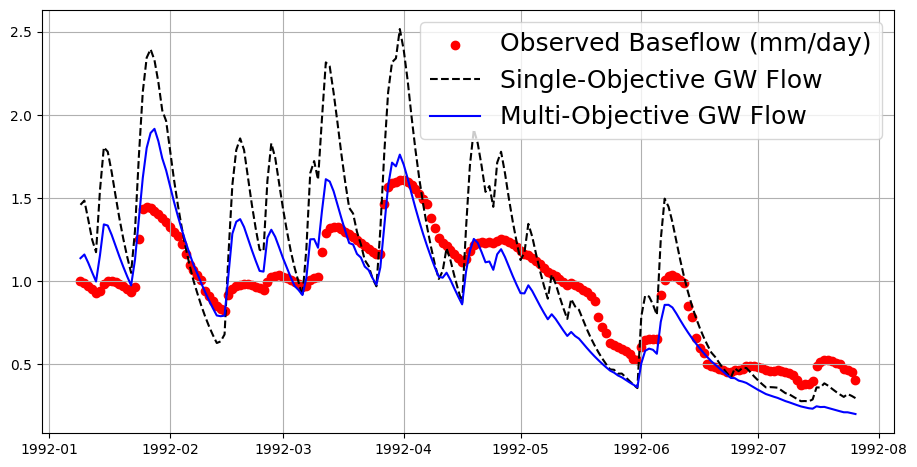

In [5]:
plt.figure(figsize=(11,5.5))

plt.scatter(df[465:665].index,df[465:665]['Observed Baseflow'],label='Observed Baseflow (mm/day)', color='red')
plt.plot(df[465:665]['Simulated GW Flow (Single)'],label='Single-Objective GW Flow', color='black',linestyle='--')
plt.plot(df[465:665]['Simulated GW Flow (Multi)'],label='Multi-Objective GW Flow', color='blue',linestyle='-')
plt.legend(fontsize=18,loc='upper right')
plt.grid()
plt.show()

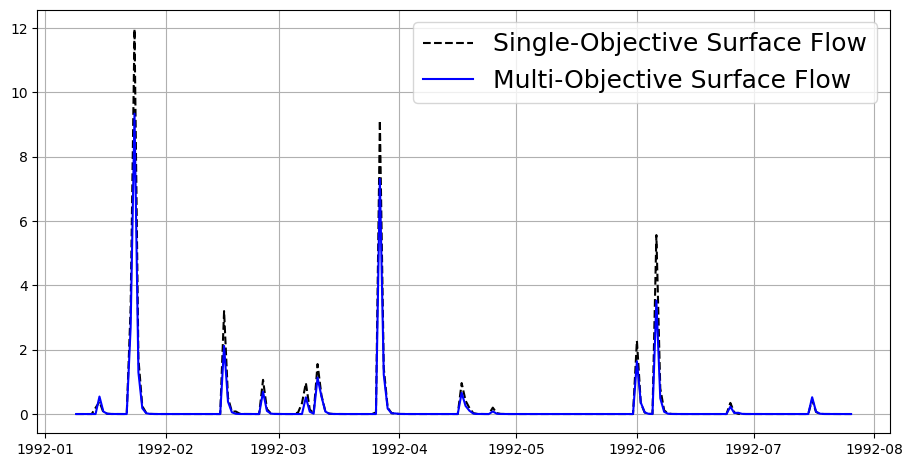

In [6]:
plt.figure(figsize=(11,5.5))

plt.plot(df[465:665]['Simulated Surface Flow (Single)'],label='Single-Objective Surface Flow', color='black',linestyle='--')
plt.plot(df[465:665]['Simulated Surface Flow (Multi)'],label='Multi-Objective Surface Flow', color='blue',linestyle='-')

plt.legend(fontsize=18,loc='upper right')
plt.grid()
plt.show()

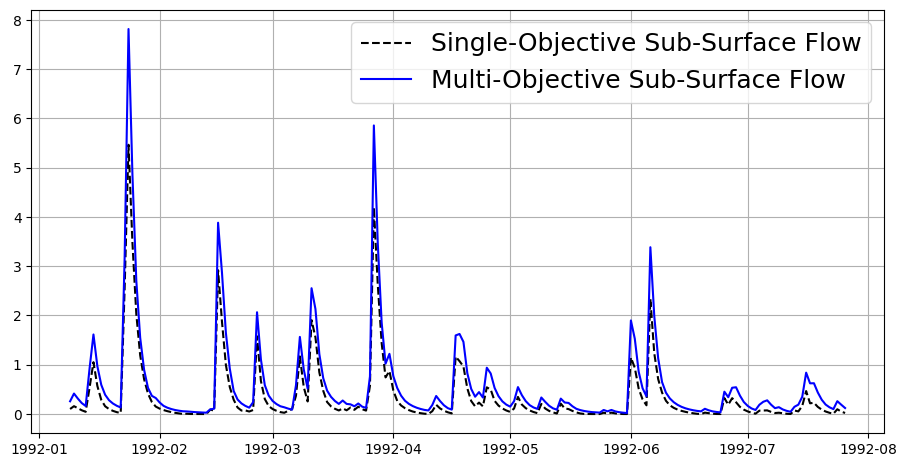

In [8]:
plt.figure(figsize=(11,5.5))

plt.plot(df[465:665]['Simulated Sub-Surface Flow (Single)'],label='Single-Objective Sub-Surface Flow', color='black',linestyle='--')
plt.plot(df[465:665]['Simulated Sub-Surface Flow (Multi)'],label='Multi-Objective Sub-Surface Flow', color='blue',linestyle='-')

plt.legend(fontsize=18,loc='upper right')
plt.grid()
plt.show()

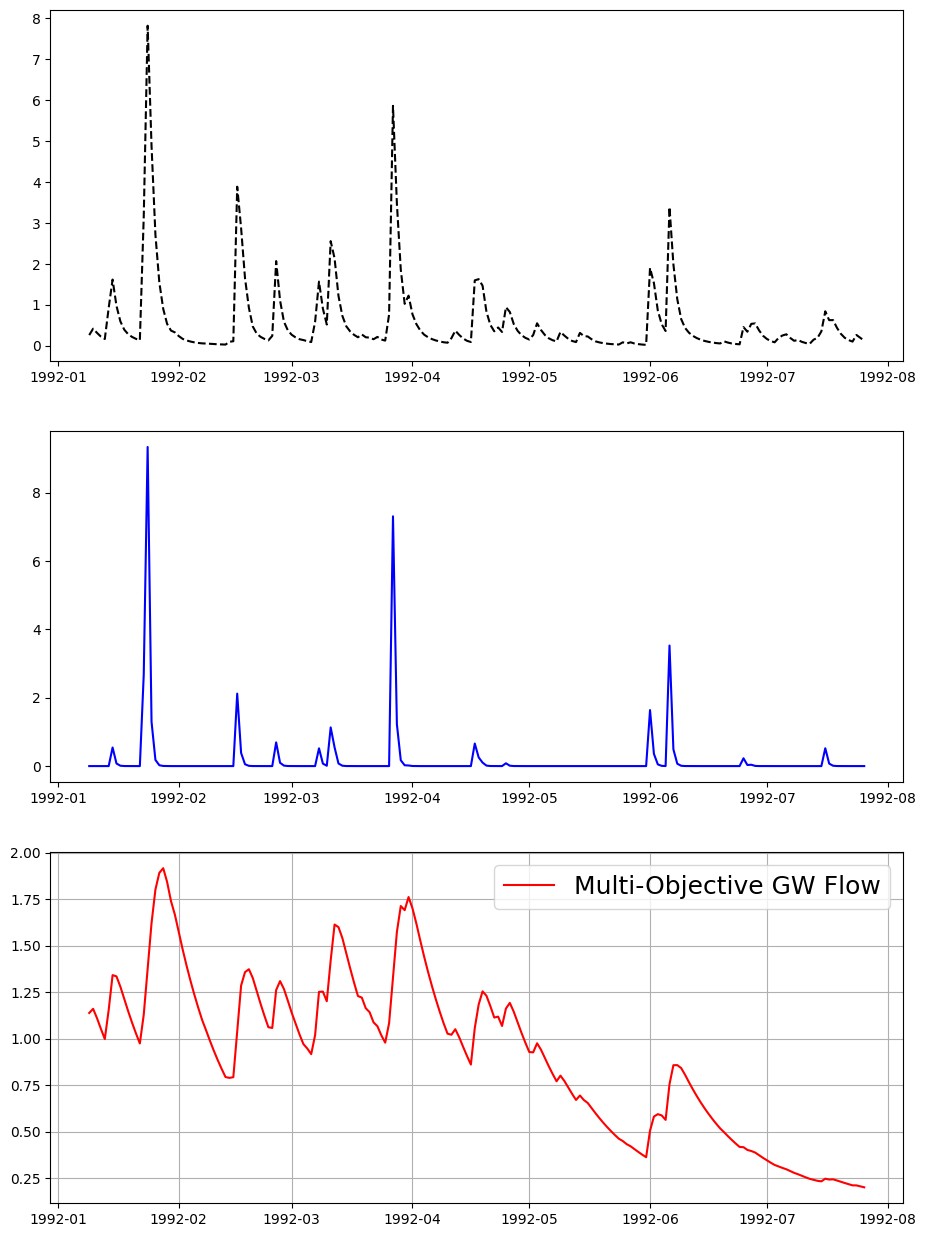

In [ ]:
plt.figure(figsize=(11,15.5))


plt.subplot(3,1,1)
plt.plot(df[465:665]['Simulated Sub-Surface Flow (Multi)'],label='Multi-Objective Sub-Surface Flow', color='black',linestyle='--')
plt.grid()
plt.subplot(3,1,2)
plt.plot(df[465:665]['Simulated Surface Flow (Multi)'],label='Multi-Objective Surface Flow', color='blue',linestyle='-')
plt.subplot(3,1,3)
plt.plot(df[465:665]['Simulated GW Flow (Multi)'],label='Multi-Objective GW Flow', color='red',linestyle='-')



In [67]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

folder= ("/home/s0shar47/scratch/OUTPUTS_Paper1/"
         "PUR/Eckhardt_Multi/Region_1/"
         "LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111"
         "/parBETA_parBETAET_/ts1989_1999/")
sfolder= ("/home/s0shar47/scratch/OUTPUTS_Paper1/"
         "PUR/OUTPUTS_PUR_Single/Region_1/"
         "LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111"
         "/parBETA_parBETAET_/ts1989_1999/")

for i in range(91):

    obs_flow= np.load(os.path.join(folder,'00060_Mean.npy'))
    obs_flow= obs_flow[:,i]

    obs_baseflow= np.load(os.path.join(folder,'baseflow.npy'))
    obs_baseflow= obs_baseflow[:,i]

    single_flow= np.load(os.path.join(sfolder,'flow_sim.npy'))
    single_flow= single_flow.squeeze()
    single_flow= single_flow[:,i]

    multi_flow= np.load(os.path.join(folder,'flow_sim.npy'))
    multi_flow= multi_flow.squeeze()
    multi_flow= multi_flow[:,i]

    single_baseflow= np.load(os.path.join(sfolder,'gwflow.npy'))
    single_baseflow= single_baseflow.squeeze()
    single_baseflow= single_baseflow[:,i]

    multi_baseflow= np.load(os.path.join(folder,'gwflow.npy'))
    multi_baseflow= multi_baseflow.squeeze()
    multi_baseflow= multi_baseflow[:,i]


    df= pd.DataFrame({'Date':pd.date_range(start='1990-10-01', end='1999-09-29', freq='1D'),
                    'Observed Flow':obs_flow.tolist(),
                    'Simulated Flow (Single)':single_flow.tolist(),
                    'Simulated Flow (Multi)':multi_flow.tolist(),
                    'Observed Baseflow':obs_baseflow.tolist(),
                    'Simulated GW Flow (Single)': single_baseflow.tolist(),
                    'Simulated GW Flow (Multi)': multi_baseflow.tolist()
                    })
    df.set_index('Date',inplace=True)

    if df['Observed Baseflow'].corr(df['Simulated GW Flow (Multi)'])>0.95:
        print(i)



9
81
84
86


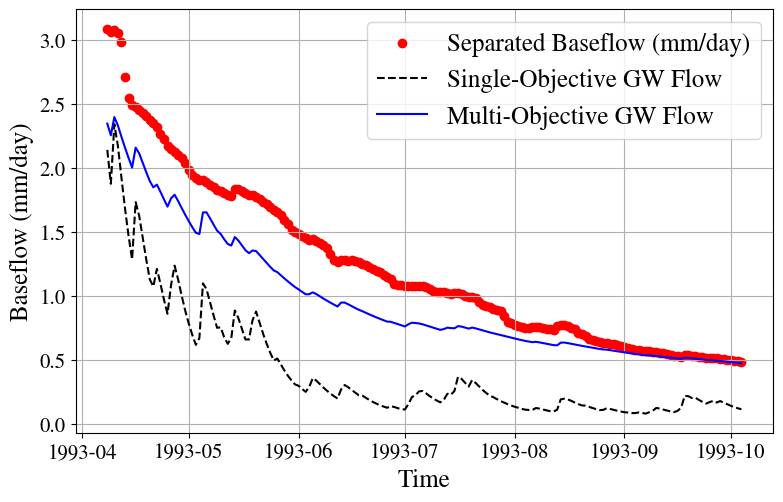

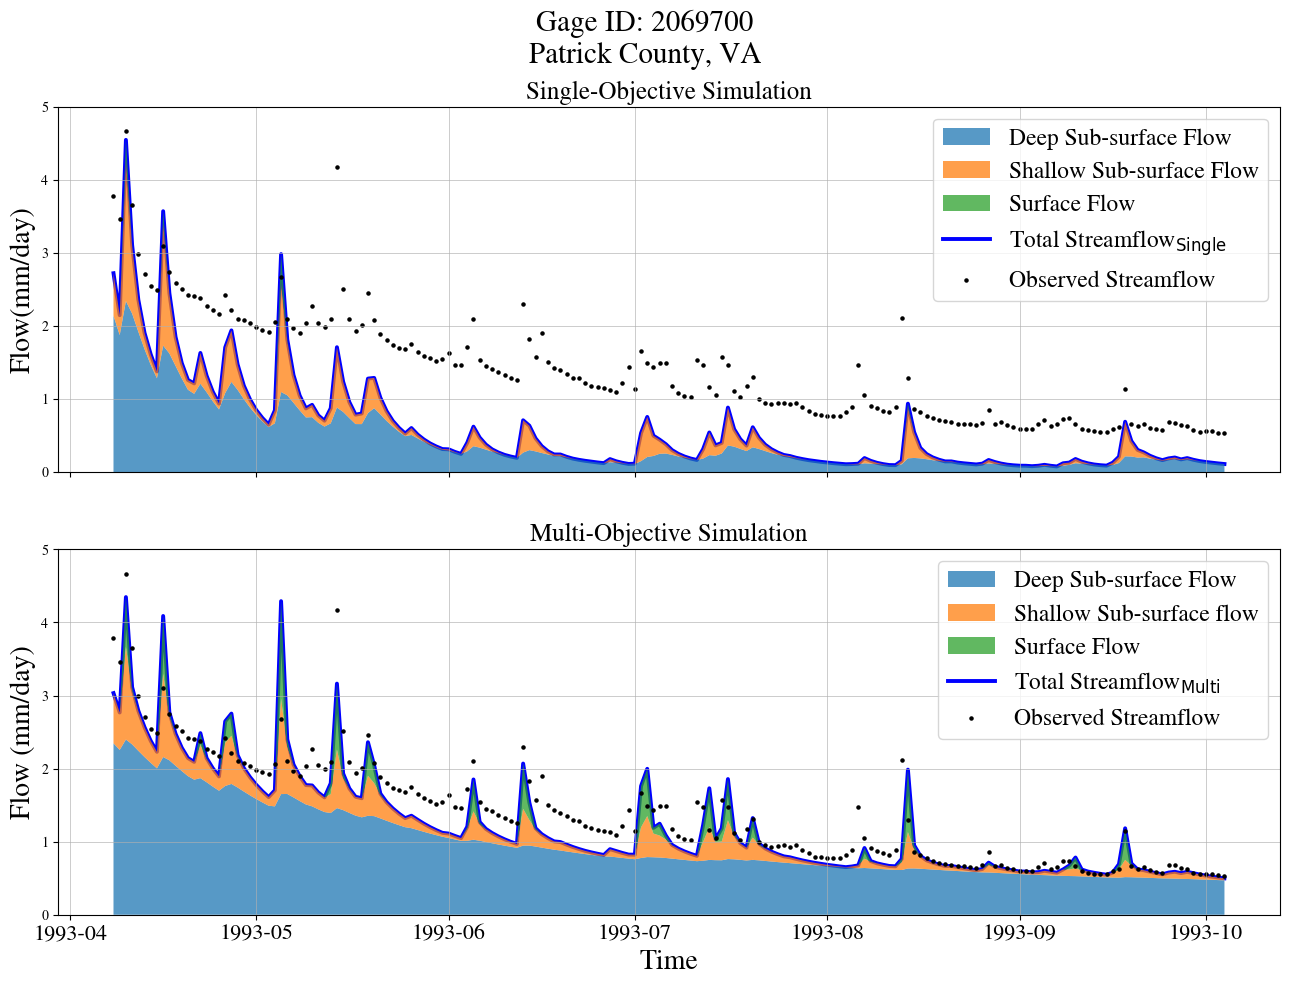

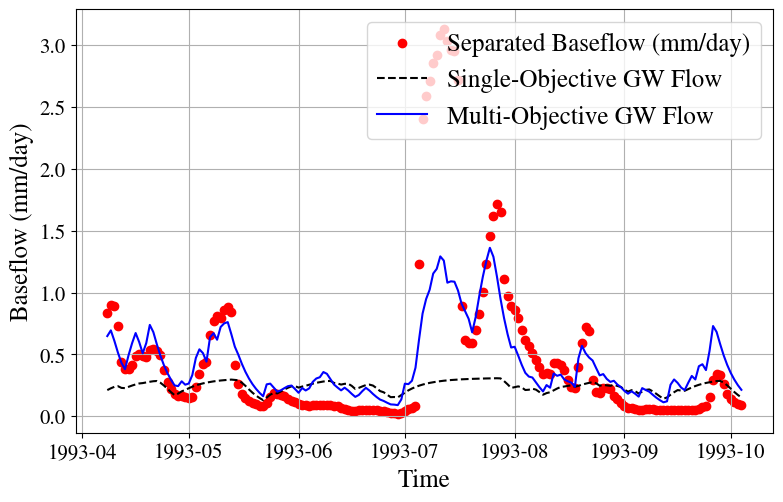

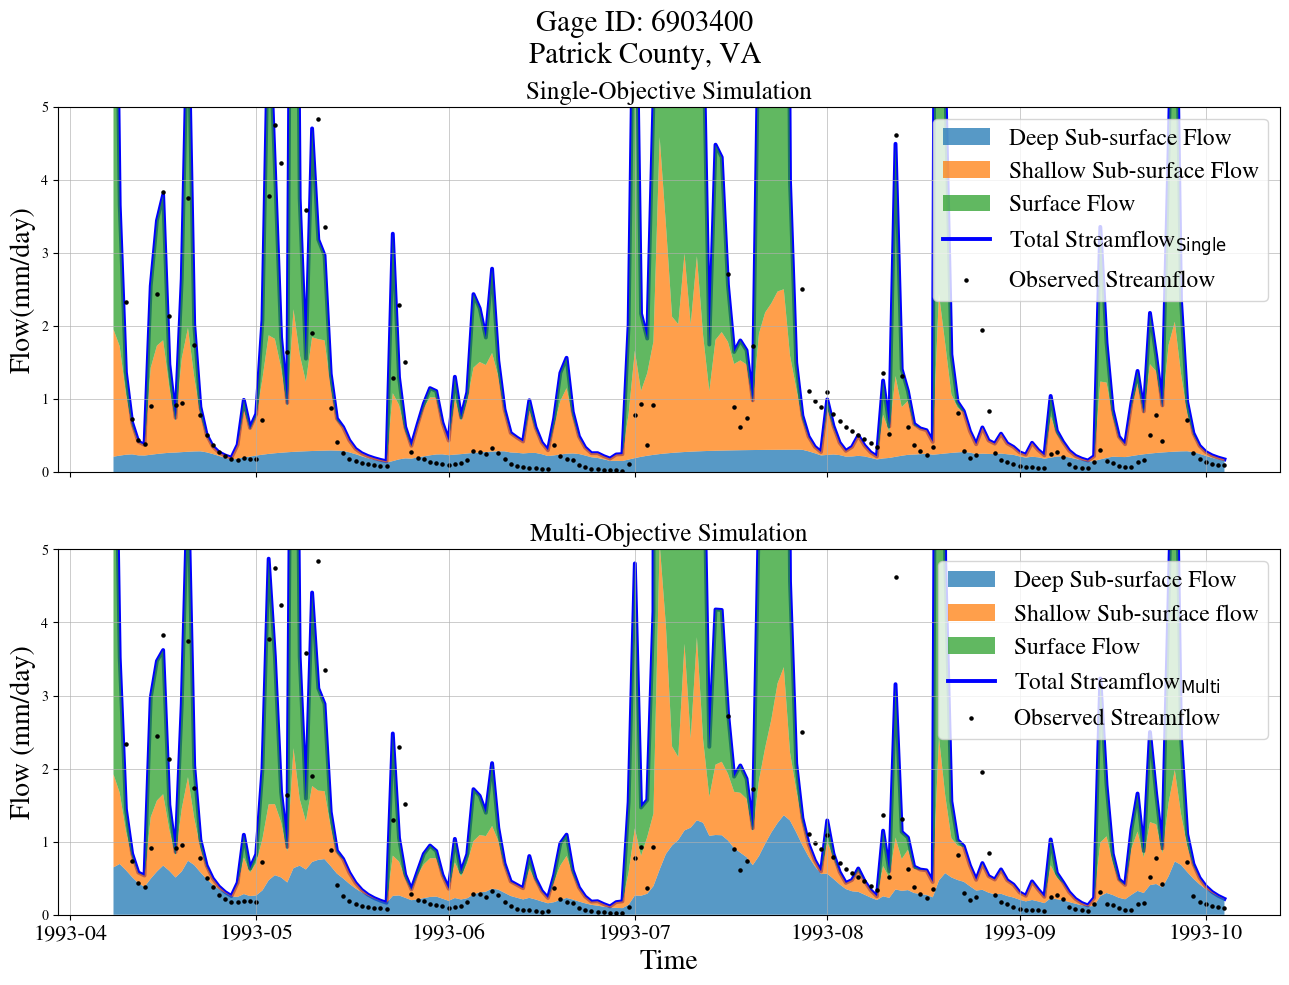

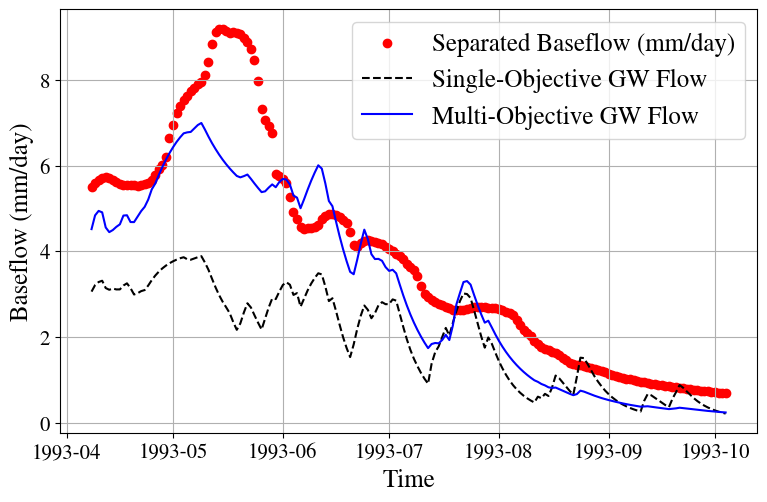

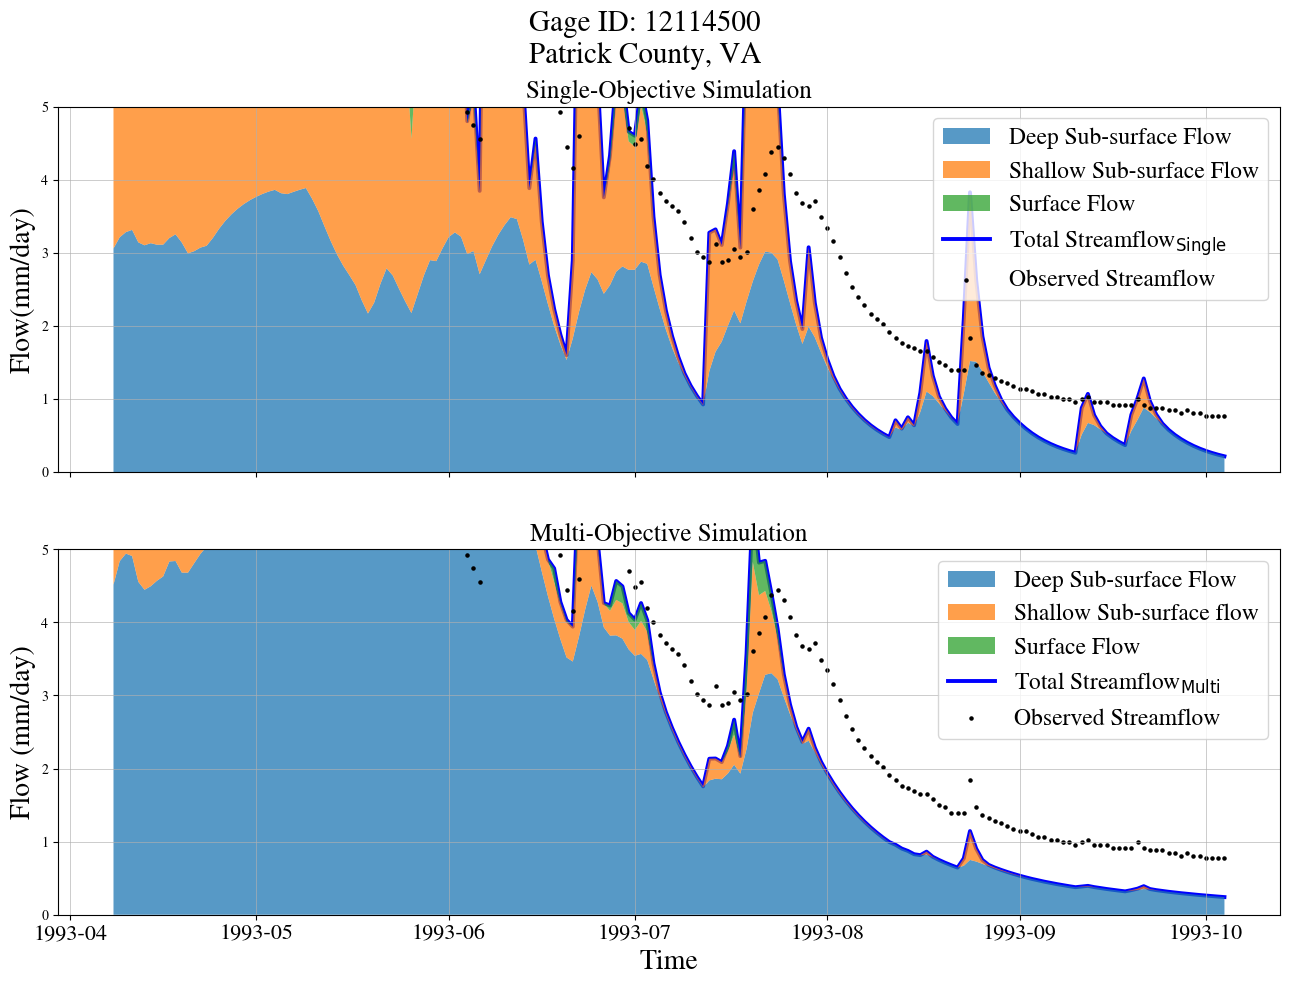

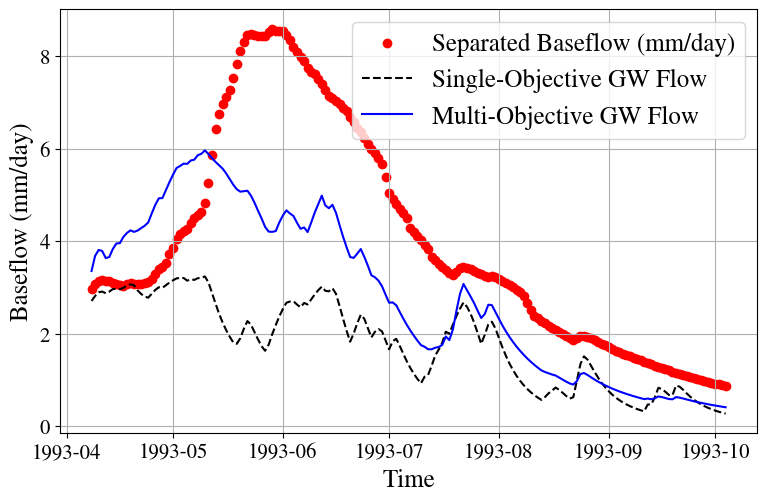

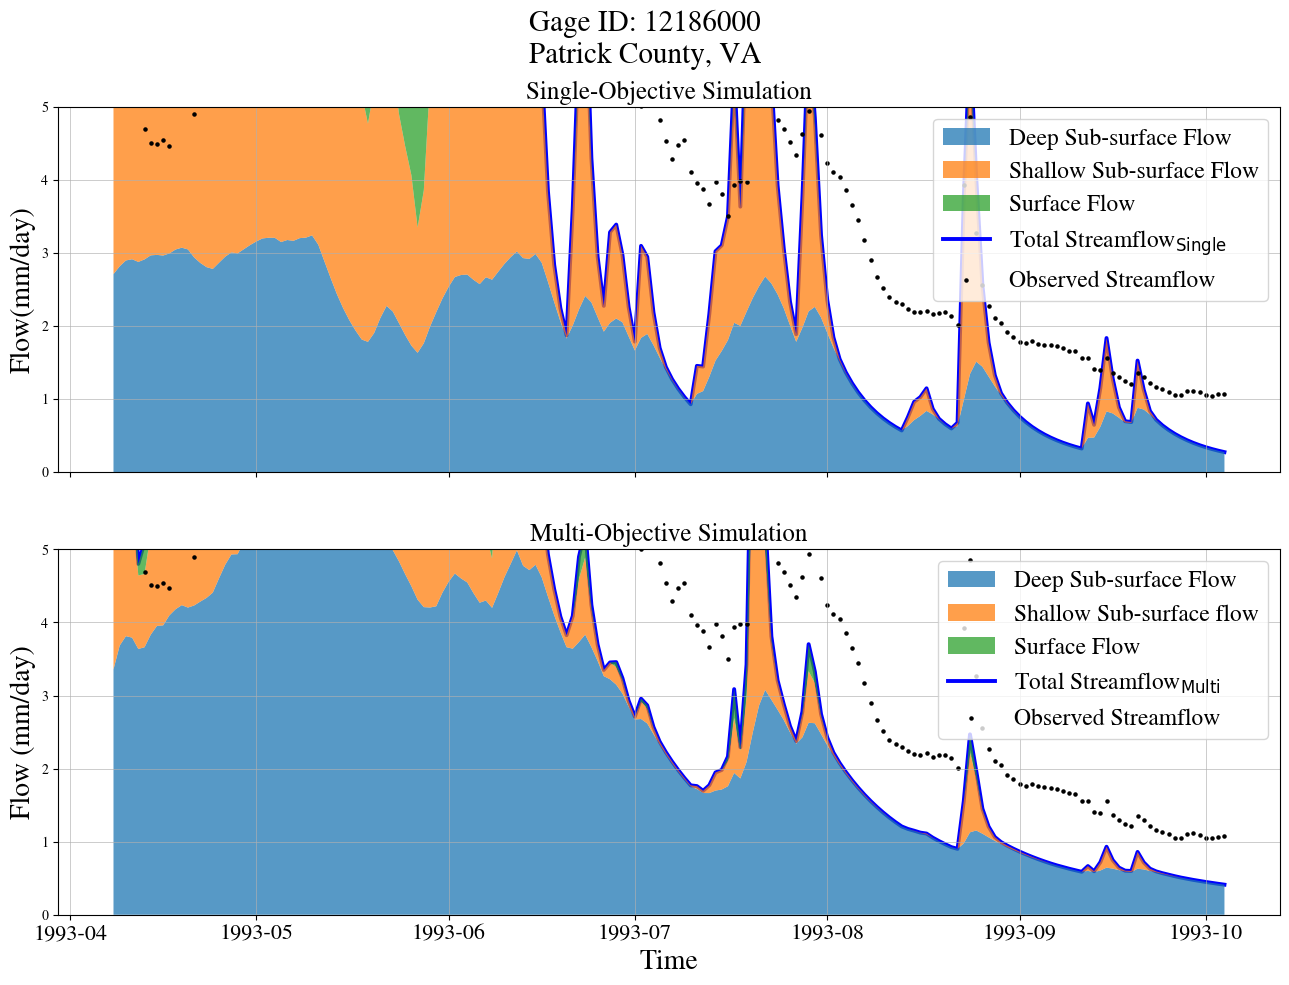

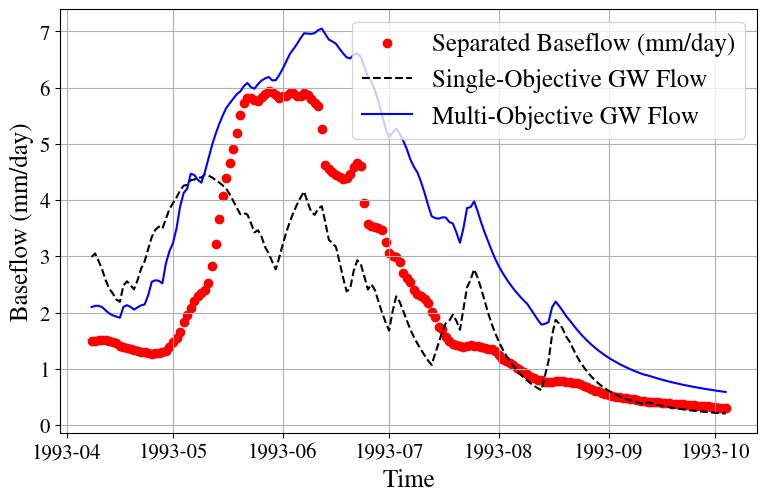

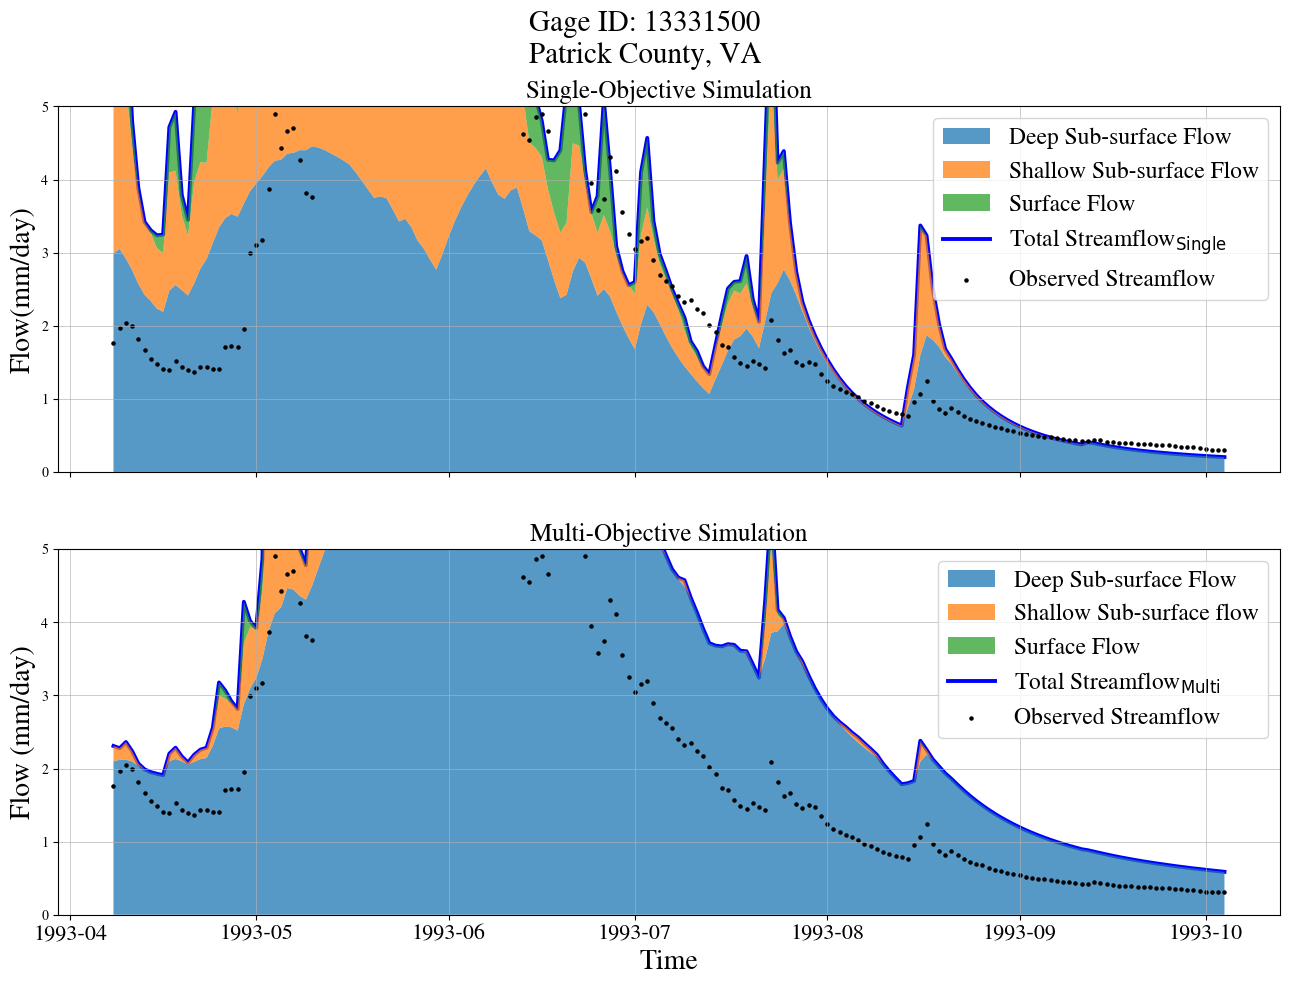

In [13]:
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
 
iss= ['2069700', '6903400', '12114500', '12186000', '13331500']
 
for k in range(1,8):
     folder= ("/home/s0shar47/scratch/OUTPUTS_Paper1/"
         f"PUR/Eckhardt_Multi/Region_{k}/"
         "LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111"
         "/parBETA_parBETAET_/ts1989_1999/")
     sfolder= ("/home/s0shar47/scratch/OUTPUTS_Paper1/"
         f"PUR/OUTPUTS_PUR_Single/Region_{k}/"
         "LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111"
         "/parBETA_parBETAET_/ts1989_1999/")
   
     obs_flow= np.load(os.path.join(folder,'00060_Mean.npy'))
 
     for i in range(obs_flow.shape[1]):
   
            gauge= np.load(f"/scratch/data/PUR_DATA/test/Region_{k}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
            gageid= gauge[i,0,14]
            gageid= str(int(gageid))
 
            if gageid in iss:
 
                gg= (gageid)
 
                obs_flow= np.load(os.path.join(folder,'00060_Mean.npy'))
                obs_flow= obs_flow[:,i]
 
                obs_baseflow= np.load(os.path.join(folder,'baseflow.npy'))
                obs_baseflow= obs_baseflow[:,i]
 
                single_flow= np.load(os.path.join(sfolder,'flow_sim.npy'))
                single_flow= single_flow.squeeze()
                single_flow= single_flow[:,i]
 
                multi_flow= np.load(os.path.join(folder,'flow_sim.npy'))
                multi_flow= multi_flow.squeeze()
                multi_flow= multi_flow[:,i]
 
                single_baseflow= np.load(os.path.join(sfolder,'gwflow.npy'))
                single_baseflow= single_baseflow.squeeze()
                single_baseflow= single_baseflow[:,i]
 
                multi_baseflow= np.load(os.path.join(folder,'gwflow.npy'))
                multi_baseflow= multi_baseflow.squeeze()
                multi_baseflow= multi_baseflow[:,i]
 
                surface_single= np.load(os.path.join(sfolder, 'srflow.npy'))
                surface_single= surface_single.squeeze()
                surface_single= surface_single[:,i]
 
                surface_multi= np.load(os.path.join(folder, 'srflow.npy'))
                surface_multi= surface_multi.squeeze()
                surface_multi= surface_multi[:,i]
 
                ssurface_single= np.load(os.path.join(sfolder, 'ssflow.npy'))
                ssurface_single= ssurface_single.squeeze()
                ssurface_single= ssurface_single[:,i]
 
                ssurface_multi= np.load(os.path.join(folder, 'ssflow.npy'))
                ssurface_multi= ssurface_multi.squeeze()
                ssurface_multi= ssurface_multi[:,i]
 
                df= pd.DataFrame({'Date':pd.date_range(start='1990-10-01', end='1999-09-29', freq='1D'),
                                'Observed Flow':obs_flow.tolist(),
                                'Simulated Flow (Single)':single_flow.tolist(),
                                'Simulated Flow (Multi)':multi_flow.tolist(),
                                'Observed Baseflow':obs_baseflow.tolist(),
                                'Simulated GW Flow (Single)': single_baseflow.tolist(),
                                'Simulated GW Flow (Multi)': multi_baseflow.tolist(),
                                'Simulated Surface Flow (Single)':surface_single.tolist(),
                                'Simulated Surface Flow (Multi)':surface_multi.tolist(),
                                'Simulated Sub-Surface Flow (Single)':ssurface_single.tolist(),
                                'Simulated Sub-Surface Flow (Multi)':ssurface_multi.tolist(),
                                })
                df.set_index('Date',inplace=True)


                plt.figure(figsize=(9,5.5))

                plt.scatter(df[920:1100].index,df[920:1100]['Observed Baseflow'],label='Separated Baseflow (mm/day)', color='red')
                plt.plot(df[920:1100]['Simulated GW Flow (Single)'],label='Single-Objective GW Flow', color='black',linestyle='--')
                plt.plot(df[920:1100]['Simulated GW Flow (Multi)'],label='Multi-Objective GW Flow', color='blue',linestyle='-')
                plt.legend(fontsize=18,loc='upper right')
                plt.xlabel("Time", fontsize=18)
                plt.xticks(fontsize=15)
                plt.yticks(fontsize=15)
                plt.ylabel("Baseflow (mm/day)", fontsize=18)
                plt.grid()
                plt.show()
 
 
                # ============================================================
                # DATA
                # ============================================================
 
                d = df.iloc[920:1100].copy()
                # d= df.copy()
                # ------------------------------------------------------------
                # SINGLE-OBJECTIVE
                # ------------------------------------------------------------
                gw_single = d['Simulated GW Flow (Single)'].values
                subsurface_single = d['Simulated Sub-Surface Flow (Single)'].values
                surface_single = d['Simulated Surface Flow (Single)'].values
 
                # Total flow
                total_single = d['Simulated Flow (Single)'].values
 
                # (    gw_single +
                #     subsurface_single +  surface_single)
 
                # ------------------------------------------------------------
                # MULTI-OBJECTIVE
                # ------------------------------------------------------------
                gw_multi = d['Simulated GW Flow (Multi)'].values
                subsurface_multi = d['Simulated Sub-Surface Flow (Multi)'].values
                surface_multi = d['Simulated Surface Flow (Multi)'].values
 
                # Total flow
                total_multi= d['Simulated Flow (Multi)'].values
                # total_multi = (
                #     gw_multi +
                #     subsurface_multi +
                #     surface_multi
                # )
 
                # ============================================================
                # FIGURE
                # ============================================================
 
                plt.rcParams['font.family'] = 'Nimbus Roman'
 
                fig, axes = plt.subplots(
                    2, 1,
                    figsize=(13, 10),
                    sharex=True
                )
 
                # ============================================================
                # SINGLE-OBJECTIVE
                # ============================================================
 
                ax = axes[0]
 
                ax.stackplot(
                    d.index,
                    gw_single,
                    subsurface_single,
                    surface_single,
                    labels=[
                        r'Deep Sub-surface Flow',
                        r'Shallow Sub-surface Flow',
                        r'Surface Flow'
                    ],
                    alpha=0.75
                )
 
                # Total discharge
                ax.plot(
                    d.index,
                    total_single,
                    color='blue',
                    linewidth=2.8,
                    label=r'Total Streamflow$_{\mathrm{Single}}$', zorder=0
                )
 
                ax.scatter(d.index,d['Observed Flow'], color='black', s=5, zorder=1, label= 'Observed Streamflow')
                # ax.scatter(d.index,d['Observed Baseflow'], color='red', s=5, zorder=1, label= 'Observed Baseflow')
 
                ax.set_ylabel('Flow(mm/day)', fontsize=20)
                ax.set_title(
                    'Single-Objective Simulation',
                    fontsize=18
                )
 
                ax.grid(
                    True,
                    which='major',
                    axis='both',
                    linestyle='-',
                    linewidth=0.5,
                    alpha=0.9
                )
 
                ax.legend(
                    fontsize=17,
                    loc='upper right',
                    frameon=True
                )
                ax.set_ylim(0,5)
                # ============================================================
                # MULTI-OBJECTIVE
                # ============================================================
 
                ax = axes[1]
 
                ax.stackplot(
                    d.index,
                    gw_multi,
                    subsurface_multi,
                    surface_multi,
                    labels=[
                        r'Deep Sub-surface Flow',
                        r'Shallow Sub-surface flow',
                        r'Surface Flow'
                    ],
                    alpha=0.75
                )
 
                # Total discharge
                ax.plot(
                    d.index,
                    total_multi,
                    color='blue',
                    linewidth=2.8,
                    label=r'Total Streamflow$_{\mathrm{Multi}}$', zorder= 0
                )
 
                ax.scatter(d.index,d['Observed Flow'], color='black', s=5, zorder=1, label= 'Observed Streamflow')
                # ax.scatter(d.index,d['Observed Baseflow'], color='red', s=5, zorder=1, label= 'Observed Baseflow')
 
                ax.set_ylabel('Flow (mm/day)', fontsize=20)
                ax.set_xlabel('Time', fontsize=20)
 
                ax.set_title(
                    '\nMulti-Objective Simulation',
                    fontsize=18
                )
 
                ax.grid(
                    True,
                    which='major',
                    axis='both',
                    linestyle='-',
                    linewidth=0.5,
                    alpha=0.9
                )
 
                ax.legend(
                    fontsize=17,
                    loc='upper right',
                    frameon=True
                )
                ax.set_ylim(0,5)
                # ============================================================
                # X-AXIS FORMATTING
                # ============================================================
 
                ax.xaxis.set_major_locator(mdates.MonthLocator())
                ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
 
                plt.setp(
                    axes[-1].get_xticklabels(),
                    rotation=0,
                    ha='center',
                    fontsize=16
                )
 
                # ============================================================
                # OVERALL TITLE
                # ============================================================
 
                plt.suptitle(
                    f"Gage ID: {gg}\nPatrick County, VA",
                    fontsize=21,
                    y=0.98
                )
 
                plt.tight_layout(rect=[0, 0, 1, 1])
 
                plt.show()
